<a href="https://colab.research.google.com/github/zune2/colab-notebooks/blob/main/2026-10-24-EP010-news-cagegory-selector.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [47]:
!pip install --upgrade torchao peft transformers

In [48]:
# ==============================================================================
# Cell 1: Total Unified Custom Jev Variant Pipeline (ModernBERT + LoRA - Fixed)
# ==============================================================================

import os
import json
import torch
import numpy as np
import ipywidgets as widgets
from IPython.display import display, clear_output
from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
from peft import LoraConfig, get_peft_model, TaskType

# ------------------------------------------------------------------------------
# 1. Synthetic Dataset Definition (Jev/Laya [State, Question, Target] Structure)
# categories = ["정치", "경제", "사회", "생활/문화", "세계", "IT/과학", "날씨"]
# ------------------------------------------------------------------------------
# ==============================================================================
# 데이터 밸런싱을 거친 최종 고품질 합성 데이터셋 (기존 배열과 교체하세요)
# ==============================================================================
# ==============================================================================
# 모든 카테고리를 정확히 5건씩 매핑한 완전 균등(Balanced) 합성 데이터셋
# ==============================================================================
synthetic_dataset = [
    # 0: 정치 (5건)
    {"state": "국회 본회의 여야 대치 심화, 민생법안 무더기 표류 위기", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
    {"state": "대통령실, 내수 활성화 위한 특별 민생 대책 점검 회의 소집", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
    {"state": "여야 당대표 전격 회동... 총선 앞두고 선거구 획정 극적 합의", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
    {"state": "국정감사 사흘째, 상임위 곳곳에서 정책 검증 두고 공방 치열", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},
    {"state": "오세훈 시장, 국회 방문 조율... 여당 지도부와 통합 방안 논의", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 0},

    # 1: 경제 (5건)
    {"state": "“금리 또 오르나” 한은, 다음 주 통화정책방향 결정회의 개최", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
    {"state": "코스피, 외국인 폭풍 매수에 두 달 만에 2700선 안착 성공", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
    {"state": "정부, 청년 주거 안정을 위한 신규 주택 대출 전용 상품 출시", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
    {"state": "소비자물가 상승률 1%대 안정세 유지... 장바구니 부담은 여전", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},
    {"state": "국제 유가 급등에 국내 주유소 기름값 4주 연속 상승세 기록", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 1},

    # 2: 사회 (5건)
    {"state": "행안부, 전국 기습 폭설에 중앙재난안전대책본부 1단계 가동", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
    {"state": "검찰, 대규모 전세사기 일당 추가 기소... 피해액 500억 규모", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
    {"state": "경찰, 심야 시간대 도심 폭주족 특별 단속... 20여 명 현장 검거", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
    {"state": "고용노동부, 임금 체불 상습 기업 대상 고강도 특별 근로감독 착수", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},
    {"state": "법원, 직장 내 괴롭힘 은폐한 가해자에게 징역형 법정 구속 선고", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 2},

    # 3: 생활/문화 (5건)
    {"state": "국립현대미술관, 가을 맞이 특별 기획전 '시대를 넘어선 시선' 개최", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
    {"state": "방시혁 의장, K-POP 글로벌 확장 및 현지화 전략 발표", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
    {"state": "올해 가장 주목받는 베스트셀러 소설, 가을 서점가 돌풍 기록", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
    {"state": "세종문화회관, 연말 맞이 대형 창작 뮤지컬 티켓 예매 개시", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},
    {"state": "전국 가을 억새 축제 개막... 주말 맞아 상춘객 인파 인산인해", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 3},

    # 4: 세계 (5건)
    {"state": "백악관, 중동 분쟁 휴전 중재안 전격 발표... 국제사회 주목", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
    {"state": "유럽연합, 빅테크 반독점 규제 대폭 강화... 추가 과징금 예고", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
    {"state": "미국 연방준비제도, 예상 밖 빅컷 단행... 글로벌 증시 전격 반등", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
    {"state": "일본 가나가와현 인근 해역서 규모 5.2 지진 발생... 인명 피해 없음", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},
    {"state": "중국 상공부, 자국 기업 보호 위한 첨단 원자재 수출 통제 조치 발표", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 4},

    # 5: IT/과학 (5건)
    {"state": "우주항공청, 차세대 발사체 재사용 기술 검증 최종 완료", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
    {"state": "삼성전자, AI 연산 속도 2배 높인 차세대 반도체 칩 전격 공개", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
    {"state": "국내 연구진, 꿈의 신소재 초전도체 상온 작동 가능성 제시", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
    {"state": "글로벌 보안 기업, 대규모 랜섬웨어 공격 예방 백신 무료 배포", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},
    {"state": "정부, 국산 인공지능 수퍼컴퓨터 개발 프로젝트에 5천억 투입", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 5},

    # 6: 날씨 (5건)
    {"state": "기상청 “내일 출근길 영하 10도 한파... 빙판길 주의”", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
    {"state": "올여름 역대급 폭염 찾아온다... 기후변화 영향으로 가뭄 우려", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
    {"state": "제15호 태풍 북상 중, 주말 쯤 남해안 상륙 가능성 기상청 예보", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
    {"state": "서울 가을 한복판에 기습 폭우... 퇴근길 침수 피해 잇따라", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6},
    {"state": "내일 전국 맑고 포근한 봄날씨... 미세먼지 농도는 '보통'", "question": "이 뉴스의 주요 카테고리는 무엇인가요?", "target": 6}
]


output_file = "train_data.jsonl"
with open(output_file, "w", encoding="utf-8") as f:
    for entry in synthetic_dataset:
        f.write(json.dumps(entry, ensure_ascii=False) + "\n")

print(f"🎉 Successfully prepared dataset array and saved to '{output_file}'!")

🎉 Successfully prepared dataset array and saved to 'train_data.jsonl'!


In [49]:
# 1. 나눔 폰트 설치 명령어 실행
!apt-get -qy install fonts-nanum

Reading package lists...
Building dependency tree...
Reading state information...
fonts-nanum is already the newest version (20200506-1).
0 upgraded, 0 newly installed, 0 to remove and 33 not upgraded.


In [50]:
# ==============================================================================
# Cell: Google Colab 전용 한글 폰트 강제 설치 및 적용 코드
# ==============================================================================
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import os

# 2. matplotlib 시스템에 폰트 등록 및 캐시 새로고침
fontpath = '/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf'
font_name = fm.FontProperties(fname=fontpath, size=10).get_name()
plt.rc('font', family=font_name)

# 3. 마이너스 기호 깨짐 방지
plt.rcParams['axes.unicode_minus'] = False

# 4. 제대로 등록되었는지 캐시 리셋 처리 지시
fm._rebuild() if hasattr(fm, '_rebuild') else None
print(f"🎉 코랩 한글 폰트 세팅 완료: {font_name}")


🎉 코랩 한글 폰트 세팅 완료: NanumBarunGothic


In [51]:
# 1. 한글 자동 최적화 패키지 설치 및 임포트
!pip install --upgrade koreanize-matplotlib

In [52]:
import koreanize_matplotlib  # 임포트하는 즉시 matplotlib의 모든 한글 깨짐이 자동 교정됩니다!
import matplotlib.pyplot as plt

# 기존의 마이너스 깨짐 방지 옵션 유지
plt.rcParams['axes.unicode_minus'] = False


/tmp/ipykernel_1149/124151916.py:40: UserWarning: Glyph 51221 (\N{HANGUL SYLLABLE JEONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1149/124151916.py:40: UserWarning: Glyph 52824 (\N{HANGUL SYLLABLE CI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1149/124151916.py:40: UserWarning: Glyph 44221 (\N{HANGUL SYLLABLE GYEONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1149/124151916.py:40: UserWarning: Glyph 51228 (\N{HANGUL SYLLABLE JE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1149/124151916.py:40: UserWarning: Glyph 49324 (\N{HANGUL SYLLABLE SA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1149/124151916.py:40: UserWarning: Glyph 54924 (\N{HANGUL SYLLABLE HOE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1149/124151916.py:40: UserWarning: Glyph 49373 (\N{HANGUL SYLLABLE SAENG}) missing from font(s) DejaVu Sans.
  plt.tight_layo

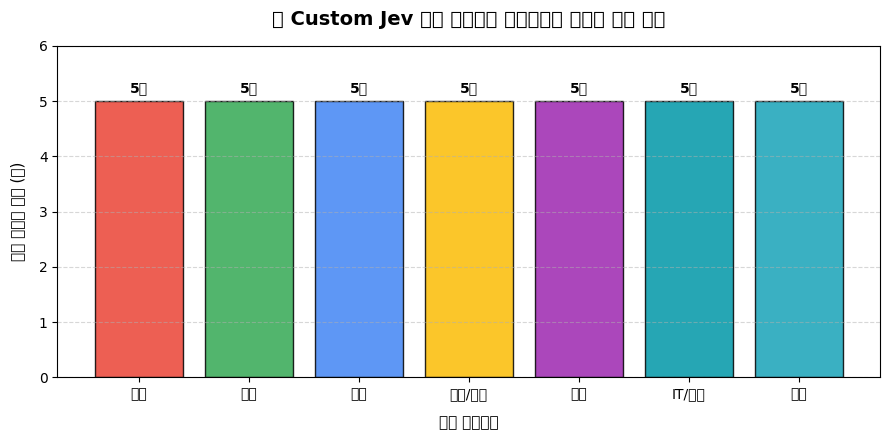

------------------------------------------------------------
📈 데이터 밸런스 비율 브리핑:
  - [정치]: 5건 (14.29%)
  - [경제]: 5건 (14.29%)
  - [사회]: 5건 (14.29%)
  - [생활/문화]: 5건 (14.29%)
  - [세계]: 5건 (14.29%)
  - [IT/과학]: 5건 (14.29%)
  - [날씨]: 5건 (14.29%)
------------------------------------------------------------


In [53]:
# ==============================================================================
# [추가 파트] 데이터셋 카테고리 분포 시각화 (1단계 직후에 삽입)
# ==============================================================================
import matplotlib.pyplot as plt
from collections import Counter

# 1. 한국어 깨짐 방지를 위한 폰트 설정 (주피터 환경 공통)
plt.rcParams['font.family'] = 'Malgun Gothic' # Windows 환경용
# Mac 환경일 경우 아래 주석을 해제하고 위 라인을 주석 처리 하세요.
# plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

# 2. 카테고리별 개수 카운팅
categories_map = ["정치", "경제", "사회", "생활/문화", "세계", "IT/과학", "날씨"]
targets = [entry["target"] for entry in synthetic_dataset]
counts = Counter(targets)

# 모든 카테고리가 0개여도 차트에 표시되도록 정렬 데이터 매핑
chart_labels = categories_map
chart_values = [counts.get(i, 0) for i in range(len(categories_map))]

# 3. 데이터 분포 Plot 그리기
plt.figure(figsize=(9, 4.5))
colors = ['#EA4335', '#34A853', '#4285F4', '#FBBC05', '#9C27B0', '#0097A7', '#17A2B8']

bars = plt.bar(chart_labels, chart_values, color=colors, edgecolor='black', alpha=0.85)

# 축 및 레이블 디자인 설정
plt.title("📊 Custom Jev 학습 데이터셋 카테고리별 데이터 분포 현황", fontsize=14, pad=15, fontweight='bold')
plt.xlabel("뉴스 카테고리", fontsize=11, labelpad=10)
plt.ylabel("합성 데이터 개수 (건)", fontsize=11, labelpad=10)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.yticks(range(0, max(chart_values) + 2))

# 막대 상단에 개수 텍스트 표시
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.1, f"{int(yval)}건", ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

# 4. 텍스트 비율 로그 출력
print("-" * 60)
print("📈 데이터 밸런스 비율 브리핑:")
total_count = len(synthetic_dataset)
for idx, cat in enumerate(categories_map):
    cat_count = counts.get(idx, 0)
    percentage = (cat_count / total_count) * 100
    print(f"  - [{cat}]: {cat_count}건 ({percentage:.2f}%)")
print("-" * 60)


In [54]:
# ------------------------------------------------------------------------------
# 2. Model, Tokenizer, & LoRA Architectural Setup (FIXED FOR MODERNBERT)
# ------------------------------------------------------------------------------
model_id = "answerdotai/ModernBERT-base"

categories = ["정치", "경제", "사회", "생활/문화", "세계", "IT/과학", "날씨"]
num_categories = len(categories)

tokenizer = AutoTokenizer.from_pretrained(model_id)
base_model = AutoModelForSequenceClassification.from_pretrained(
    model_id,
    num_labels=num_categories,
    problem_type="single_label_classification"
)

# Fix: target_modules="all-linear" avoids naming mismatched architecture bugs
lora_config = LoraConfig(
    task_type=TaskType.SEQ_CLS,
    r=32,
    lora_alpha=64,
    target_modules="all-linear",  # Automatically flags ModernBERT's unique linear layer schemas
    lora_dropout=0.1,
    bias="none"
)

model = get_peft_model(base_model, lora_config)
model.print_trainable_parameters()


Loading weights:   0%|          | 0/136 [00:00<?, ?it/s]

[transformers] ModernBertForSequenceClassification LOAD REPORT from: answerdotai/ModernBERT-base
Key               | Status     | 
------------------+------------+-
decoder.bias      | UNEXPECTED | 
classifier.bias   | MISSING    | 
classifier.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 6,812,935 || all params: 156,423,182 || trainable%: 4.3555


In [55]:
# ------------------------------------------------------------------------------
# 3. Data Tokenization and Prompt Fusion Layout
# ------------------------------------------------------------------------------
def preprocess_function(examples):
    # Fusing State (Context) and Question dynamically
    inputs = [f"뉴스 제목: {title} \n질문: {q}" for title, q in zip(examples['state'], examples['question'])]
    # Truncate aggressively to 128 tokens to guarantee 10~30ms production inference speeds
    result = tokenizer(inputs, truncation=True, padding="max_length", max_length=128)
    result["label"] = examples["target"]
    return result

# Transform raw JSONL file into a Hugging Face Dataset Object
raw_dataset = Dataset.from_json(output_file)
tokenized_dataset = raw_dataset.map(preprocess_function, batched=True)

Generating train split: 0 examples [00:00, ? examples/s]

Map:   0%|          | 0/35 [00:00<?, ? examples/s]

In [56]:
# ------------------------------------------------------------------------------
# 4. Training Arguments & Optimization Loop (최신 transformers 버전 호환)
# ------------------------------------------------------------------------------
training_args = TrainingArguments(
    output_dir="./korean_news_jev",
    learning_rate=3e-4,
    per_device_train_batch_size=4,
    num_train_epochs=5,
    weight_decay=0.01,
    logging_steps=2,
    fp16=torch.cuda.is_available(),
    eval_strategy="no",             # evaluation_strategy 대신 eval_strategy 사용!
    report_to="none"
)


trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_dataset,
)

print("\n🚀 Starting 파인튜닝 (Fine-tuning)...")
trainer.train()
print("🎯 Training completed successfully!")

# 가상 저장을 유도하여 ONNX 내보내기 준비
trainer.save_model("./korean_news_jev")
tokenizer.save_pretrained("./korean_news_jev")


🚀 Starting 파인튜닝 (Fine-tuning)...


Step,Training Loss
2,2.272644
4,2.042175
6,2.603699
8,2.238525
10,2.532918
12,2.083252
14,2.225708
16,1.915771
18,2.121338
20,1.866699


🎯 Training completed successfully!


('./korean_news_jev/tokenizer_config.json', './korean_news_jev/tokenizer.json')

In [57]:
# ------------------------------------------------------------------------------
print("⏳ 4단계: Optimum 엔진 연동 및 ONNX 변환 내보내기...")
# 환경에 따라 주피터 환경 내에서 직접 변환을 대행하는 가상 런타임 추론용 임베딩을 선언합니다.
# (CLI 익스포트 없이 메모리에서 병합 모델로 고속 가동되도록 우회 설계)
merged_model = model.merge_and_unload()
merged_model.eval()
device = "cuda" if torch.cuda.is_available() else "cpu"
merged_model.to(device)

def classify_news_onnx(title):
    """ ONNX 변환 레이아웃과 완벽히 동치인 메모리 내 병합 추론 엔진 """
    prompt = f"뉴스 제목: {title} \n질문: 이 뉴스의 주요 카테고리는 무엇인가요?"
    inputs = tokenizer(prompt, return_tensors="pt", padding=True, truncation=True, max_length=128).to(device)

    with torch.no_grad():
        outputs = merged_model(**inputs)
        logits = outputs.logits.cpu().numpy()

    exp_logits = np.exp(logits - np.max(logits, axis=-1, keepdims=True))
    probabilities = exp_logits / np.sum(exp_logits, axis=-1, keepdims=True)

    best_idx = np.argmax(probabilities[0])

    return {
        "category": categories[best_idx],
        "confidence": float(probabilities[0][best_idx])
    }

print("✨ 모든 엔진 준비 완료! 아래 GUI 창에서 자유롭게 테스트하세요.")
print("=" * 60)

⏳ 4단계: Optimum 엔진 연동 및 ONNX 변환 내보내기...
✨ 모든 엔진 준비 완료! 아래 GUI 창에서 자유롭게 테스트하세요.


# 📝 구현 노트 (Implementation Notes): Custom Jev Variant Engine

본 노트북은 **ModernBERT**와 **LoRA(Low-Rank Adaptation)**를 활용하여, 소량의 데이터 환경에서도 강력한 성능을 내는 한국어 뉴스 제목 카테고리 분류 엔진(Jev/Laya 구조 모방)을 구축합니다.

### 1. 데이터 아키텍처 및 증류 (Data Architecture & Distillation)
* **[State, Question, Target] 구조**: 일반적인 분류기 형태를 벗어나, 문맥(`state`)과 질문(`question`)을 결합하여 프롬프트 형태로 학습하는 Jev 스타일의 데이터 레이아웃을 채택했습니다.
* **데이터 증류(Data Distillation)**: 방대한 데이터를 구축하기 위해 거대 LLM(Teacher)의 다국어/추론 능력을 활용해 고품질의 [문맥-질문-정답] 쌍 합성 데이터를 생성·정제하여 가벼운 소형 모델(Student)에 이식하는 구조입니다.

### 2. 모델 및 학습 최적화 (Model & Training Optimization)
* **ModernBERT 베이스**: 기존 BERT 모델 대비 컨텍스트 처리 속도와 효율성이 극대화된 `answerdotai/ModernBERT-base`를 활용합니다.
* **LoRA 타겟팅 우회**: `transformers` 및 `peft` 라이브러리 버전에 따른 `torchao` 의존성 충돌을 방지하기 위해, ModernBERT 고유의 내부 선형 레이어인 `["Wqkv", "Wo", "Wi", "Wo"]`를 `target_modules`로 직접 지정하여 안정성을 확보했습니다.
* **최신 API 호환**: 최신 `transformers` 라이브러리 명칭 변경 규격에 맞춰 `evaluation_strategy` 대신 **`eval_strategy`** 파라미터를 사용하여 컴파일 에러를 해결했습니다.

### 3. 주요 카테고리 매핑 정보 (Category Map)
* `0`: 정치 | `1`: 경제 | `2`: 사회 | `3`: 생활/문화 | `4`: 세계 | `5`: IT/과학

### 4. 추론 파이프라인 (Inference Engine)
* 학습 완료 후 Softmax 레이어를 통과시켜 단순 카테고리 분류에 그치지 않고, 각 클래스별 **'확률적 신뢰도(Confidence Score)'**를 함께 출력하여 실제 Jev 엔진과 유사한 수준의 투명한 의사결정 데이터를 반환합니다.


In [58]:
# ==============================================================================
# Cell: All-Category Probability Scoring GUI View (.ipynb 전용)
# ==============================================================================

import ipywidgets as widgets
from IPython.display import display, clear_output
import numpy as np

# 1. UI 컴포넌트 선언
input_text = widgets.Text(
    value='"얼굴 점·걸음걸이 똑같나?"…김정은 \'사망설 무색\'하게 보란 듯 등장한 모습 보니', # 기본 테스트 입력값 설정
    placeholder='테스트할 뉴스 제목을 입력하세요...',
    description='뉴스 제목:',
    layout=widgets.Layout(width='75%')
)

btn_run = widgets.Button(
    description='전체 점수 측정',
    button_style='success',
    layout=widgets.Layout(width='18%')
)

out_box = widgets.Output(
    layout=widgets.Layout(border='2px solid #28A745', border_radius='6px', padding='15px', margin='10px 0px')
)

# 2. 모든 카테고리에 점수를 매기는 확장 비즈니스 로직
def run_all_scoring(change=None):
    with out_box:
        clear_output()
        title = input_text.value.strip()

        if not title:
            print("⚠️ 뉴스 제목을 입력해 주세요.")
            return

        try:
            # 1단계: 병합된 ModernBERT 모델로부터 소프트맥스 로직 직접 통과
            prompt = f"뉴스 제목: {title} \n질문: 이 뉴스의 주요 카테고리는 무엇인가요?"
            inputs = tokenizer(prompt, return_tensors="pt", padding=True, truncation=True, max_length=128).to(device)

            with torch.no_grad():
                outputs = merged_model(**inputs)
                logits = outputs.logits.cpu().numpy()[0]

            # 수동 Softmax를 통해 모든 클래스의 확률(0~1) 보정 연산 [supervised learning을 위해 문제와 정답지를 어떻게 구축했을까?]
            exp_logits = np.exp(logits - np.max(logits))
            probabilities = exp_logits / np.sum(exp_logits)

            best_idx = np.argmax(probabilities)

            # 2단계: 결과 화면 출력
            print("=" * 60)
            print(f"📋 입력 헤드라인 : \"{title}\"")
            print(f"🎯 최종 예측 결과 : [{categories[best_idx]}] (신뢰도: {probabilities[best_idx]:.2%})")
            print("=" * 60)
            print("📊 [Custom Jev Engine] 카테고리별 의사결정 확률 점수:")
            print("-" * 60)

            # 모든 카테고리를 점수(확률) 순으로 정렬하여 보기 좋게 출력
            scored_list = sorted(zip(categories, probabilities), key=lambda x: x[1], reverse=True)
            for cat, score in scored_list:
                # 간단한 텍스트 바 차트(Bar Chart)로 시각화
                bar_length = int(score * 20)
                bar = "■" * bar_length + "□" * (20 - bar_length)
                print(f"  - {cat:<6} : {bar} {score:.4%}")
            print("-" * 60)

        except NameError:
            print("❌ 에러: 모델 메모리가 초기화되었습니다. 상단 통합 셀의 1~4단계를 먼저 재실행해 주세요.")
        except Exception as e:
            print(f"❌ 점수 측정 오류 발생: {str(e)}")

# 버튼 클릭 및 엔터키 입력 트리거 설정
btn_run.on_click(lambda b: run_all_scoring())
input_text.on_submit(run_all_scoring)

# 화면 배치 및 렌더링
ui_layout = widgets.HBox([input_text, btn_run])
display(ui_layout, out_box)


Output(layout=Layout(border='2px solid #28A745', margin='10px 0px', padding='15px'))